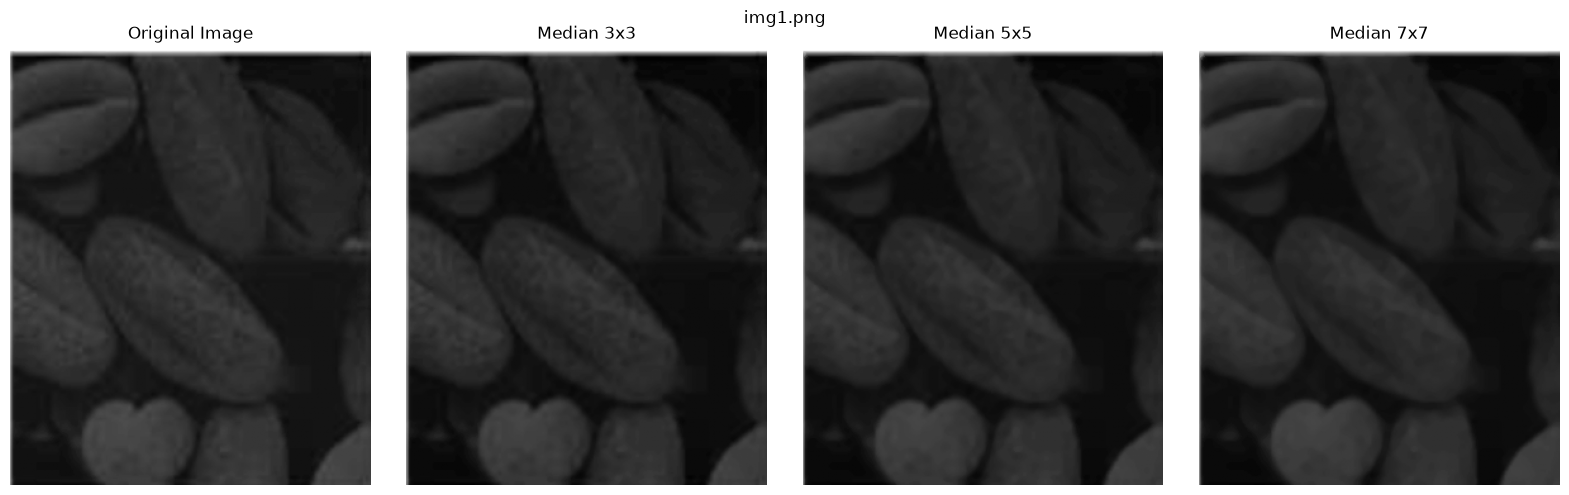

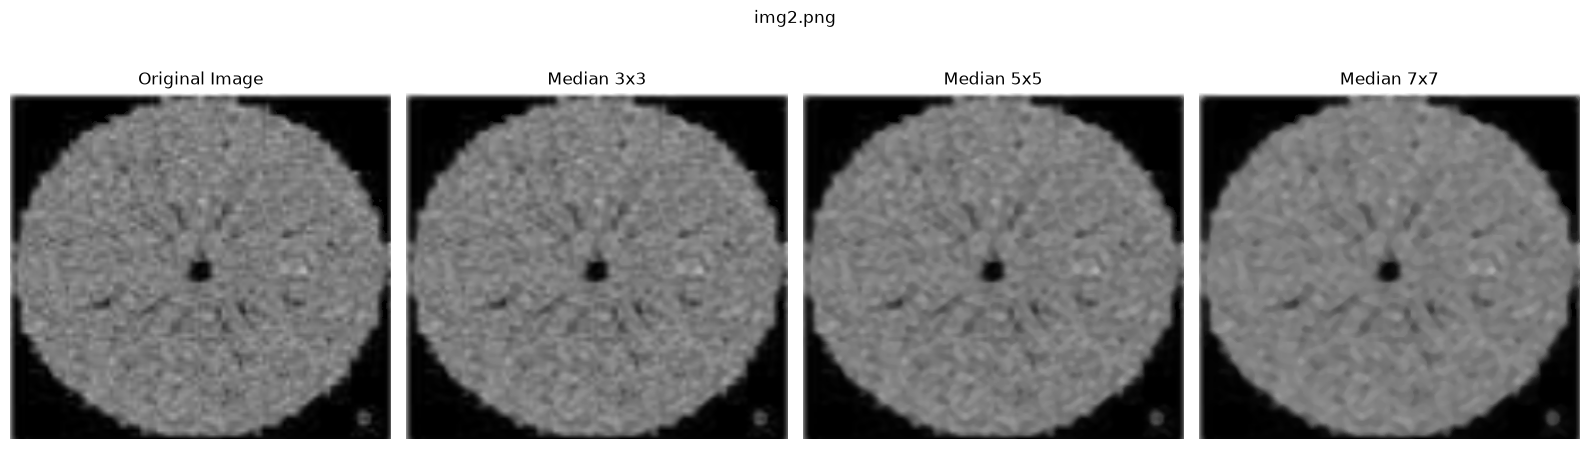

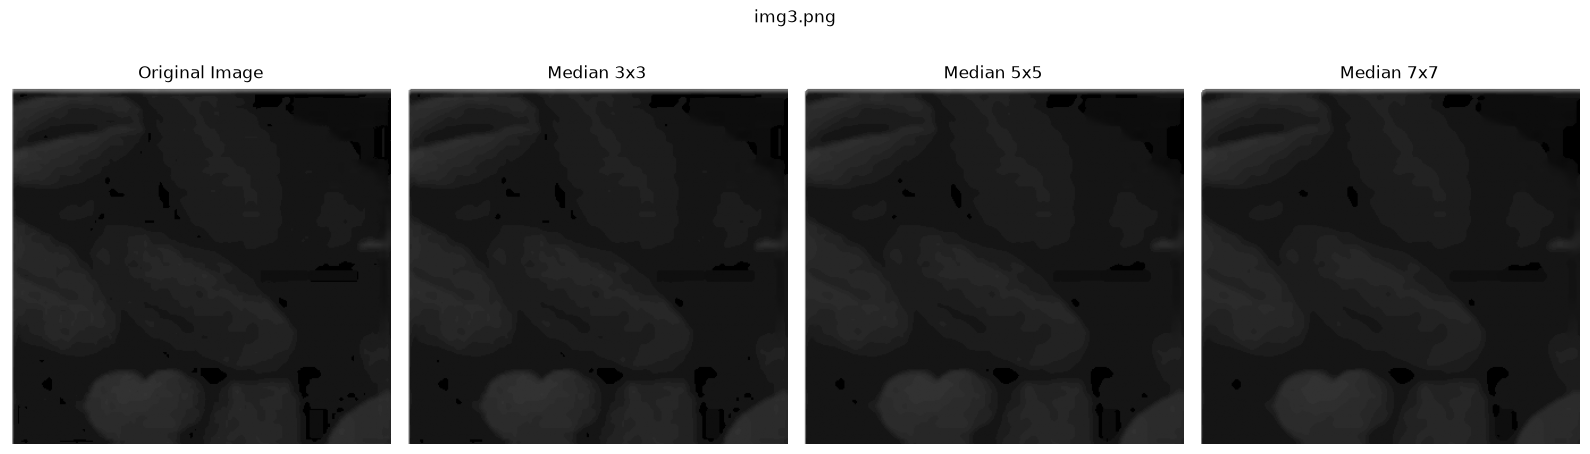

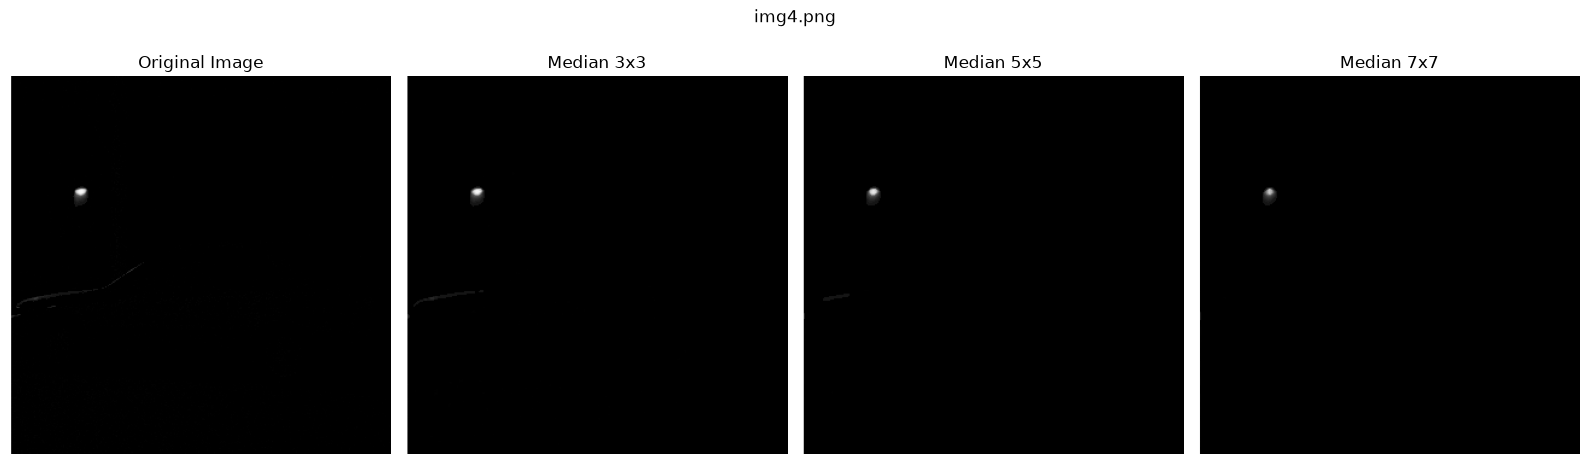

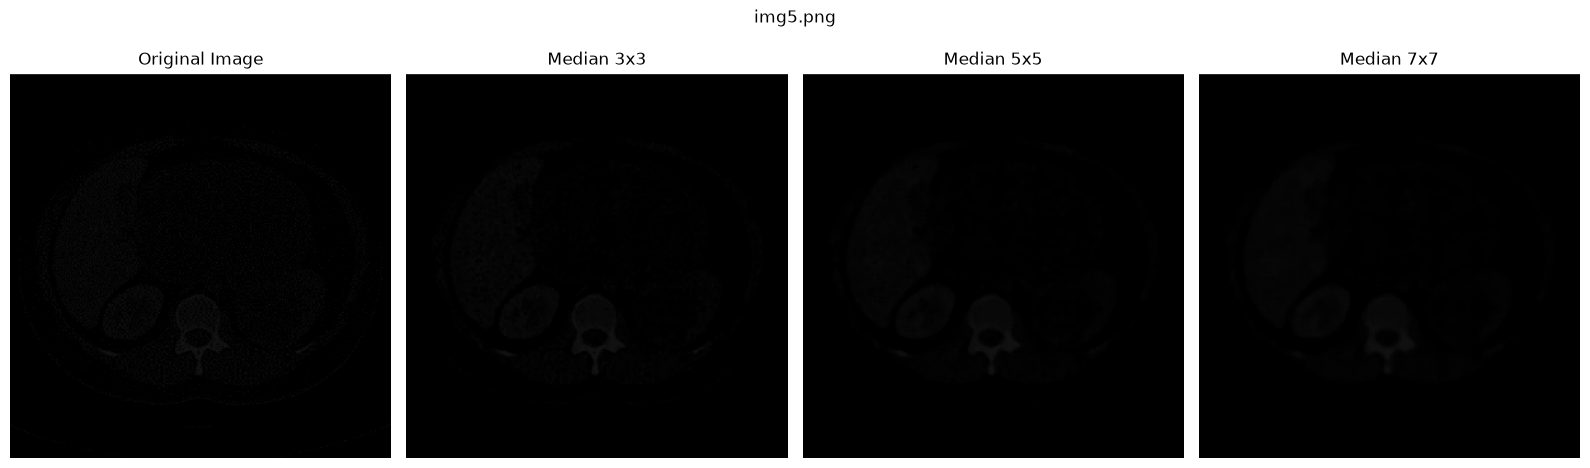

   Image Filter Size   Sharpness  Processing Time
img1.png         3x3   32.159839         0.001042
img1.png         5x5   31.597940         0.001155
img1.png         7x7   30.813392         0.010679
img2.png         3x3   61.624317         0.000123
img2.png         5x5   58.589664         0.000778
img2.png         7x7   54.902313         0.011006
img3.png         3x3  245.223315         0.000124
img3.png         5x5  241.351276         0.000862
img3.png         7x7  237.637661         0.006100
img4.png         3x3 1029.188551         0.000078
img4.png         5x5 1024.154713         0.000600
img4.png         7x7 1019.556052         0.005890
img5.png         3x3 1080.843653         0.000081
img5.png         5x5 1074.786998         0.000706
img5.png         7x7 1073.506676         0.005482


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
image_names = [
    "img1.png",
    "img2.png",
    "img3.png",
    "img4.png",
    "img5.png"
]

# Median filter sizes
filter_sizes = [3, 5, 7]
results = []
for image_name in image_names:

    # Read image in grayscale
    image = cv2.imread(image_name, 0)
    filtered_images = [image]
    titles = ["Original Image"]

    # Apply different median filters
    for size in filter_sizes:
        start_time = time.time()
        filtered = cv2.medianBlur(image, size)
        processing_time = time.time() - start_time
        filtered_images.append(filtered)
        titles.append(f"Median {size}x{size}")

        # Calculate sharpness
        sharpness = cv2.Laplacian(
            filtered, cv2.CV_64F
        ).var()

        results.append({
            "Image": image_name,
            "Filter Size": f"{size}x{size}",
            "Sharpness": sharpness,
            "Processing Time": processing_time
        })

    # Display original and filtered results
    plt.figure(figsize=(16, 5))

    for j in range(4):

        plt.subplot(1, 4, j + 1)
        plt.imshow(filtered_images[j], cmap="gray")
        plt.title(titles[j])
        plt.axis("off")

    plt.suptitle(image_name)
    plt.tight_layout()
    plt.show()


# Display comparison report
if results:
    report = pd.DataFrame(results)
    print(report.to_string(index=False))